In [38]:
from tensorflow import keras
import tensorflow as tf
from tensorflow.keras.utils import plot_model
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import plot_confusion_matrix, ConfusionMatrixDisplay, confusion_matrix
import seaborn as sns

In [39]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

train_ankit = {'images': x_train, 'labels': y_train}
test_ankit = {'images': x_test, 'labels': y_test}

In [4]:
train_ankit

{'images': array([[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        ...,
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ...,

In [5]:
test_ankit

{'images': array([[[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        ...,
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         ...,
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0]],
 
        [[0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ..., 0, 0, 0],
         [0, 0, 0, ...,

In [6]:
# Initial Exploration

print("Training data shape: ", train_ankit['images'].shape)
print("Testing data shape: ", test_ankit['images'].shape)
print("Image resolution: ", train_ankit['images'][0].shape)
print("Largest pixel value: ", np.amax(train_ankit['images']))

Training data shape:  (60000, 28, 28)
Testing data shape:  (10000, 28, 28)
Image resolution:  (28, 28)
Largest pixel value:  255


In [7]:
# Normalize the pixel values in the dataset to a range between 0-1
train_ankit['images'] = train_ankit['images'] / 255
test_ankit['images'] = test_ankit['images'] / 255

In [8]:
# One-hot encode the labels
train_ankit['labels'] = tf.keras.utils.to_categorical(train_ankit['labels'], 10)
test_ankit['labels'] = tf.keras.utils.to_categorical(test_ankit['labels'], 10)

In [9]:
# Display the shape of the train_data['labels'] and test_data['labels']
print("Train labels shape: ", train_ankit['labels'].shape)
print("Test labels shape: ", test_ankit['labels'].shape)

Train labels shape:  (60000, 10)
Test labels shape:  (10000, 10)


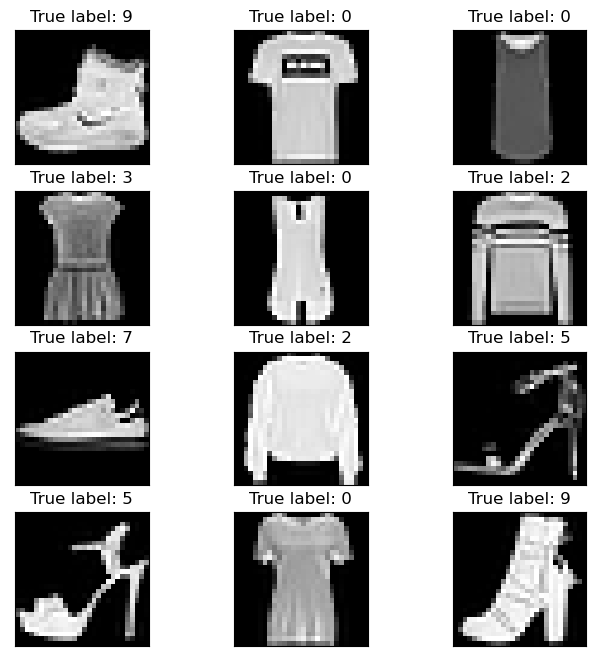

In [10]:
# Visualization
def plot_image(image, label):
    plt.imshow(image, cmap='gray')
    plt.title(f"True label: {label}")
    plt.xticks([])
    plt.yticks([])

# Plot the first 12 data samples in the training dataset
plt.figure(figsize=(8,8))
for i in range(12):
    plt.subplot(4, 3, i+1)
    plot_image(train_ankit['images'][i], np.argmax(train_ankit['labels'][i]))
plt.show()

In [11]:
# Training Data by splitting it into 80% training and 20% validation
random_state = 16
x_train_ankit, x_val_ankit, y_train_ankit, y_val_ankit = train_test_split(train_ankit['images'], train_ankit['labels'], test_size=0.2, random_state=random_state)

In [12]:
# Build the model
cnn_model_ankit = tf.keras.models.Sequential()
cnn_model_ankit.add(tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
cnn_model_ankit.add(tf.keras.layers.MaxPooling2D((2, 2)))
cnn_model_ankit.add(tf.keras.layers.Conv2D(32, (3, 3), activation='relu'))
cnn_model_ankit.add(tf.keras.layers.MaxPooling2D((2, 2)))
cnn_model_ankit.add(tf.keras.layers.Flatten())
cnn_model_ankit.add(tf.keras.layers.Dense(100, activation='relu'))
cnn_model_ankit.add(tf.keras.layers.Dense(10, activation='softmax'))

In [13]:
# Compile the model
cnn_model_ankit.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [14]:
# Printing Model Summary
cnn_model_ankit.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 13, 13, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 11, 11, 32)        9248      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 5, 5, 32)         0         
 2D)                                                             
                                                                 
 flatten (Flatten)           (None, 800)               0         
                                                                 
 dense (Dense)               (None, 100)               8

In [15]:
import keras.utils.vis_utils
from importlib import reload
reload(keras.utils.vis_utils)

<module 'keras.utils.vis_utils' from 'C:\\Users\\ANKIT\\AppData\\Roaming\\Python\\Python39\\site-packages\\keras\\utils\\vis_utils.py'>

In [16]:
from keras.utils.vis_utils import plot_model    
plot_model(cnn_model_ankit, to_file='cnn_model_ankit.png', show_shapes=True, show_layer_names=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [17]:
# Train and validate the model
cnn_history_ankit = cnn_model_ankit.fit(x_train_ankit, y_train_ankit, epochs=8, batch_size=256, validation_data=(x_val_ankit, y_val_ankit))

Epoch 1/8
188/188 [==============================] - 42s 165ms/step - loss: 0.7468 - accuracy: 0.7377 - val_loss: 0.5038 - val_accuracy: 0.8102
Epoch 2/8
188/188 [==============================] - 31s 164ms/step - loss: 0.4412 - accuracy: 0.8375 - val_loss: 0.3967 - val_accuracy: 0.8653
Epoch 3/8
188/188 [==============================] - 31s 165ms/step - loss: 0.3831 - accuracy: 0.8621 - val_loss: 0.3568 - val_accuracy: 0.8757
Epoch 4/8
188/188 [==============================] - 31s 164ms/step - loss: 0.3453 - accuracy: 0.8748 - val_loss: 0.3378 - val_accuracy: 0.8836
Epoch 5/8
188/188 [==============================] - 31s 164ms/step - loss: 0.3230 - accuracy: 0.8826 - val_loss: 0.3260 - val_accuracy: 0.8863
Epoch 6/8
188/188 [==============================] - 31s 164ms/step - loss: 0.3036 - accuracy: 0.8888 - val_loss: 0.3108 - val_accuracy: 0.8905
Epoch 7/8
188/188 [==============================] - 31s 164ms/step - loss: 0.2913 - accuracy: 0.8935 - val_loss: 0.3160 - val_accuracy:

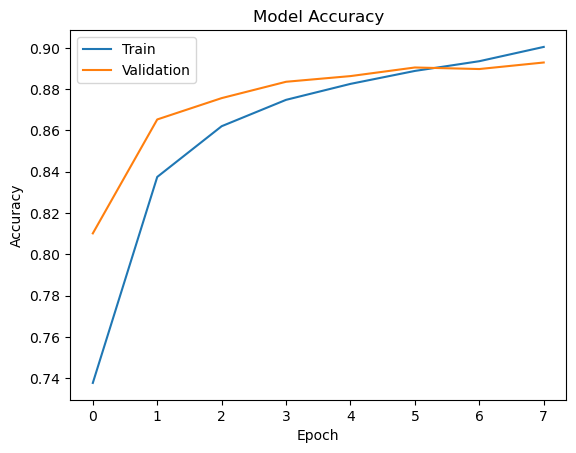

In [19]:
# Plot training & validation accuracy values
plt.plot(cnn_history_ankit.history['accuracy'])
plt.plot(cnn_history_ankit.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [20]:
test_loss, test_accuracy = cnn_model_ankit.evaluate(test_ankit['images'], test_ankit['labels'], verbose=0)
print("Test Accuracy:", test_accuracy)

cnn_predictions_ankit = cnn_model_ankit.predict(test_ankit['images'])

#Convert prediction probabilities into integers
y_preds = cnn_predictions_ankit.argmax(axis=1)
test_ankit['labels'][0]

Test Accuracy: 0.8860999941825867
313/313 [==============================] - 3s 8ms/step


array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.], dtype=float32)

In [21]:
# 4. Create a function that plots the probability distribution of the predictions as a histogram
class_labels = [0,1,2,3,4,5,6,7,8,9]
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
def plot_image(i, predictions_array, true_label, img):
  predictions_array, true_label, img = predictions_array[i], true_label[i], img[i]
  plt.grid(False)
  plt.xticks([])
  plt.yticks([])
  
  plt.imshow(img, cmap=plt.cm.binary)

  predicted_label = np.argmax(predictions_array)
  if predicted_label == true_label:
    color = 'green'
  else:
    color = 'blue'
  
  plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                100*np.max(predictions_array),
                                class_names[true_label]),
                                color=color)

def plot_value_array(i, predictions_array, true_label):
  predictions_array, true_label = predictions_array[i], true_label[i]
  plt.grid(False)
  plt.xticks(range(10), class_labels)
  plt.yticks([])
  thisplot = plt.bar(range(10), predictions_array, color="#777777")
  plt.ylim([0, 1]) 
  predicted_label = np.argmax(predictions_array)
 
  thisplot[predicted_label].set_color('blue')
  thisplot[true_label].set_color('green')

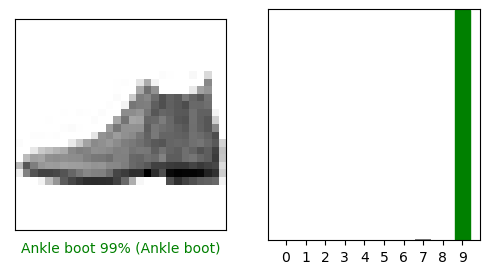

In [22]:
i = 0
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i,cnn_predictions_ankit, y_test, test_ankit['images'])
plt.subplot(1,2,2)
plot_value_array(i,cnn_predictions_ankit, y_test)
plt.show()


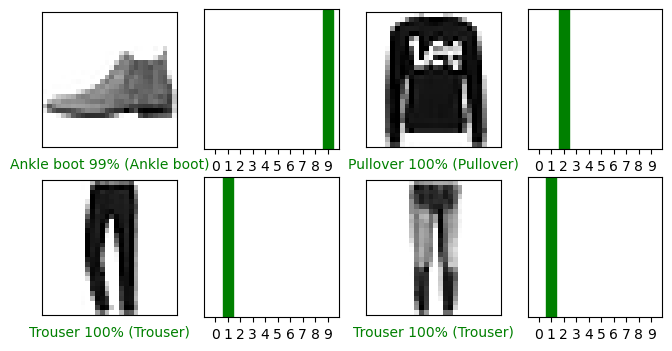

In [23]:

num_rows = 2
num_cols = 2
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i,cnn_predictions_ankit, y_test, test_ankit['images'])
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i,cnn_predictions_ankit, y_test)
plt.show()

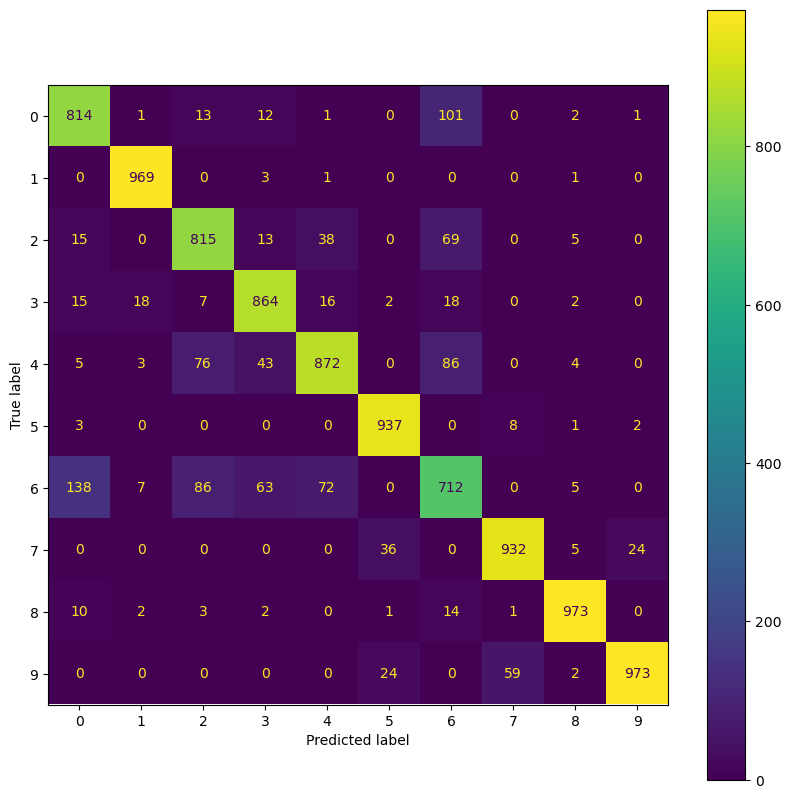

In [24]:

#Confusion matrix
cm=confusion_matrix(y_preds,y_test)
#Plot
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_labels)
fig, ax = plt.subplots(figsize=(10,10))
disp.plot(ax=ax);



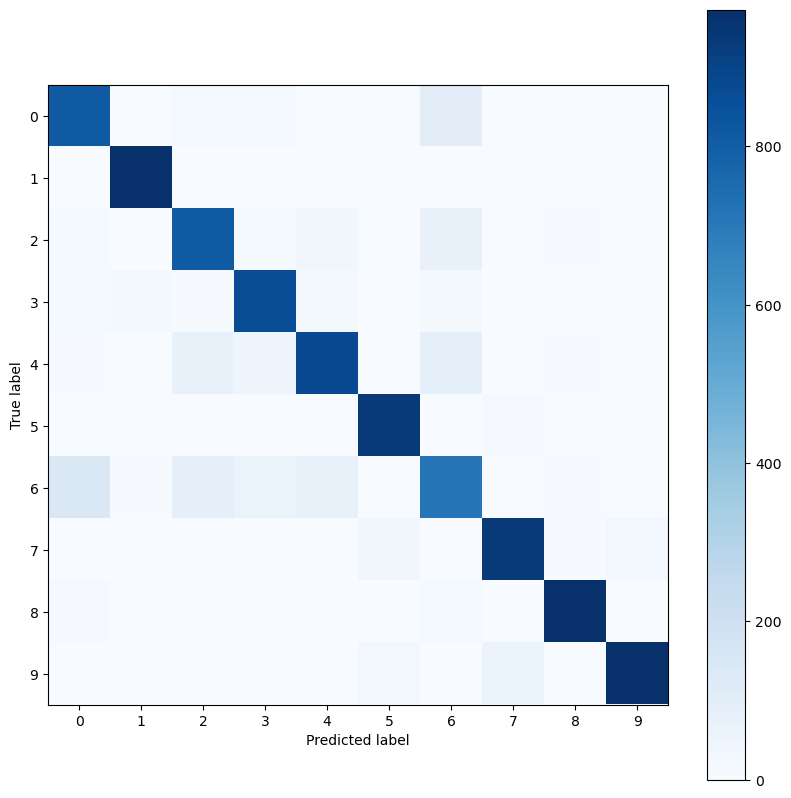

In [25]:
# Plot with Matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar()
tick_marks = np.arange(10)
plt.xticks(tick_marks, range(10))
plt.yticks(tick_marks, range(10))
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

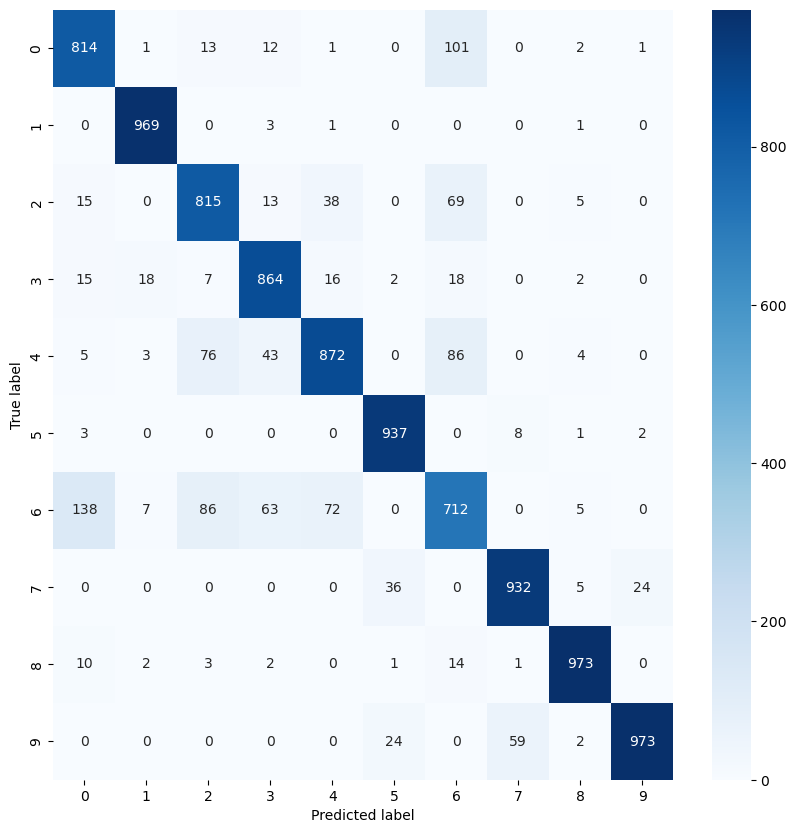

In [26]:
# Plot with Seaborn
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

In [27]:
# Build,Train,Validate,Test and Analyze RNN Model

# Define the model
rnn_model_ankit = keras.models.Sequential([
    keras.layers.LSTM(128, input_shape=(28, 28), return_sequences=False),
    keras.layers.Dense(10, activation='softmax')
])

# Compile the model
rnn_model_ankit.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [28]:
# Print a summary of the model
rnn_model_ankit.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 128)               80384     
                                                                 
 dense_2 (Dense)             (None, 10)                1290      
                                                                 
Total params: 81,674
Trainable params: 81,674
Non-trainable params: 0
_________________________________________________________________


In [29]:
plot_model(rnn_model_ankit, to_file='rnn_model_ankit.png', show_shapes=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [30]:
# Train and validate the model
rnn_history_ankit = rnn_model_ankit.fit(x_train_ankit, y_train_ankit, epochs=8, batch_size=256, validation_data=(x_val_ankit, y_val_ankit))

Epoch 1/8
188/188 [==============================] - 37s 175ms/step - loss: 0.7993 - accuracy: 0.7074 - val_loss: 0.5591 - val_accuracy: 0.7952
Epoch 2/8
188/188 [==============================] - 32s 168ms/step - loss: 0.4951 - accuracy: 0.8166 - val_loss: 0.4600 - val_accuracy: 0.8321
Epoch 3/8
188/188 [==============================] - 32s 169ms/step - loss: 0.4459 - accuracy: 0.8334 - val_loss: 0.4239 - val_accuracy: 0.8484
Epoch 4/8
188/188 [==============================] - 32s 168ms/step - loss: 0.4060 - accuracy: 0.8488 - val_loss: 0.3903 - val_accuracy: 0.8551
Epoch 5/8
188/188 [==============================] - 32s 168ms/step - loss: 0.3821 - accuracy: 0.8580 - val_loss: 0.3812 - val_accuracy: 0.8605
Epoch 6/8
188/188 [==============================] - 32s 168ms/step - loss: 0.3659 - accuracy: 0.8644 - val_loss: 0.3629 - val_accuracy: 0.8674
Epoch 7/8
188/188 [==============================] - 32s 168ms/step - loss: 0.3544 - accuracy: 0.8701 - val_loss: 0.3657 - val_accuracy:

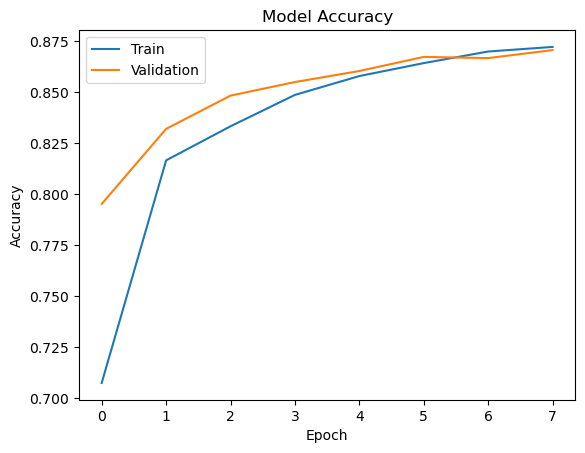

In [31]:
# Plot training & validation accuracy values
plt.plot(rnn_history_ankit.history['accuracy'])
plt.plot(rnn_history_ankit.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [32]:
test_loss, test_accuracy = rnn_model_ankit.evaluate(test_ankit['images'], test_ankit['labels'], verbose=0)
print("Test Accuracy:", test_accuracy)

rnn_predictions_ankit = rnn_model_ankit.predict(test_ankit['images'])

#Converting prediction probabilities into integers
y_pred = rnn_predictions_ankit.argmax(axis=1)
test_ankit['labels'][0]

Test Accuracy: 0.8644999861717224
313/313 [==============================] - 6s 16ms/step


array([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.], dtype=float32)

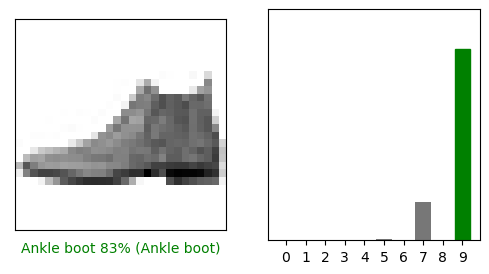

In [33]:
i = 0
plt.figure(figsize=(6,3))
plt.subplot(1,2,1)
plot_image(i,rnn_predictions_ankit, y_test, test_ankit['images'])
plt.subplot(1,2,2)
plot_value_array(i,rnn_predictions_ankit, y_test)
plt.show()

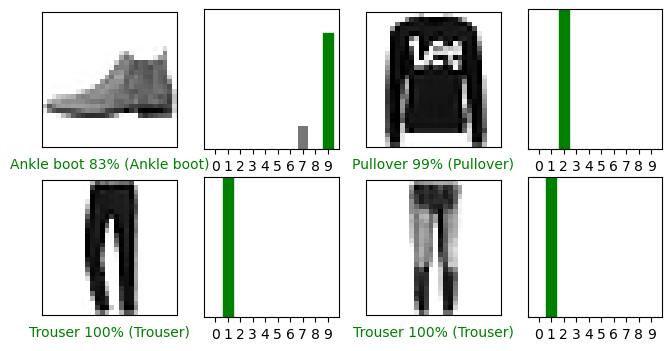

In [34]:
num_rows = 2
num_cols = 2
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_image(i,rnn_predictions_ankit, y_test, test_ankit['images'])
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_value_array(i,rnn_predictions_ankit, y_test)
plt.show()

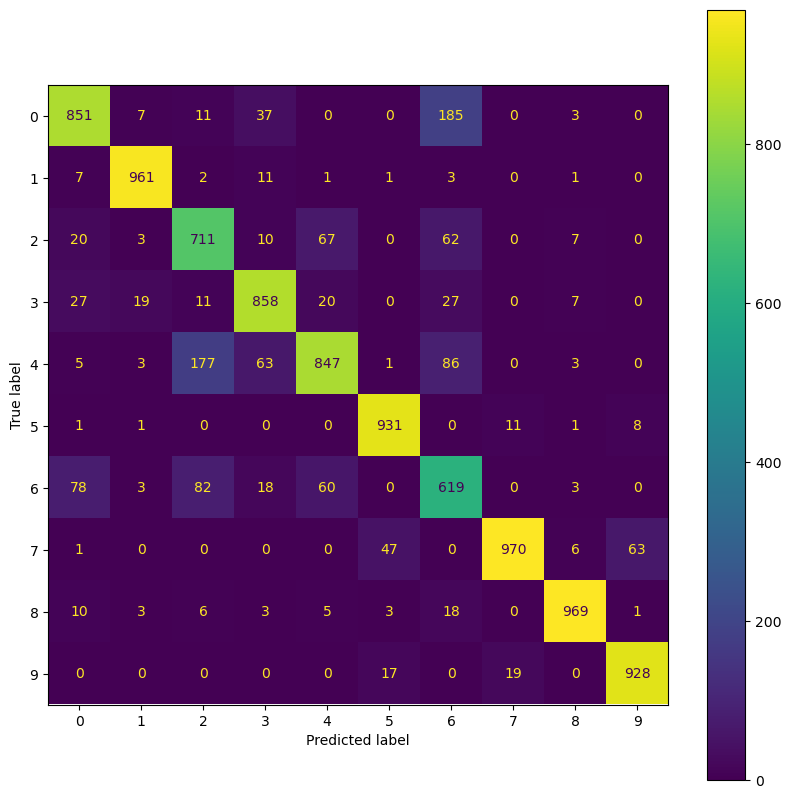

In [35]:
#Confusion matrix
cm_rnn=confusion_matrix(y_pred,y_test)
#Plot
disp=ConfusionMatrixDisplay(confusion_matrix=cm_rnn,display_labels=class_labels)
fig, ax = plt.subplots(figsize=(10,10))
disp.plot(ax=ax);

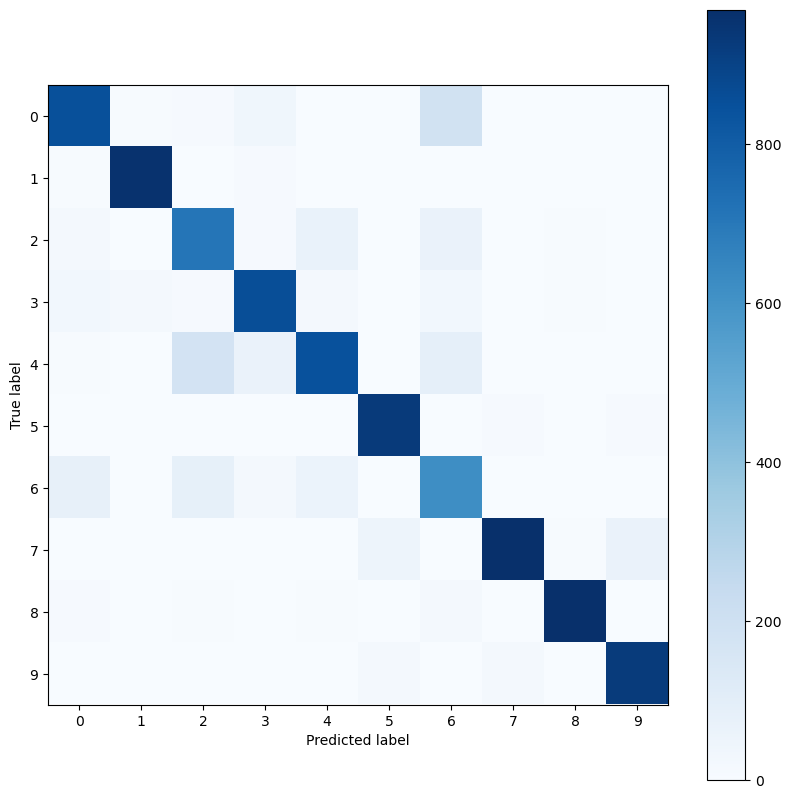

In [36]:
# Plot with Matplotlib
plt.figure(figsize=(10, 10))
plt.imshow(cm_rnn, interpolation='nearest', cmap=plt.cm.Blues)
plt.colorbar()
tick_marks = np.arange(10)
plt.xticks(tick_marks, range(10))
plt.yticks(tick_marks, range(10))
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

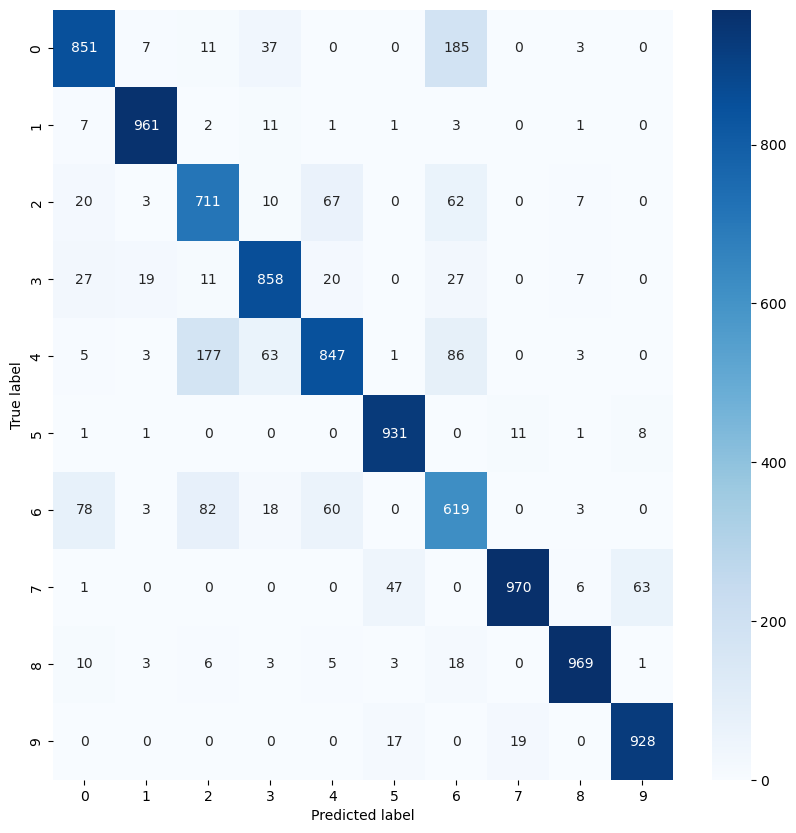

In [37]:
# Plot with Seaborn
plt.figure(figsize=(10, 10))
sns.heatmap(cm_rnn, annot=True, cmap='Blues', fmt='g', xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()